<a href="https://colab.research.google.com/github/amyashima27-ops/C-lculo.Num-rico/blob/main/tarefa_gauss.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Aproximação inicial e tolerância
x, y, z = 0.0, 0.0, 0.0
tol = 1e-5
max_iter = 100

k = 0
diff = float("inf")

# Iterações do método de Gauss-Seidel
while diff >= tol and k < max_iter:
    k += 1
    x_old, y_old, z_old = x, y, z

    # Fórmulas iterativas
    x = (6.0 + y_old - 2.0 * z_old) / 10.0
    y = (22.0 + x + z_old) / 11.0
    z = (-10.0 - 2.0 * x + y) / 10.0

    # Critério de paragem: norma infinito da diferença
    diff = max(abs(x - x_old), abs(y - y_old), abs(z - z_old))

# Apresentação dos resultados
print(f"Número de iterações realizadas: {k}")
print(f"Solução aproximada obtida: x = {x:.6f}, y = {y:.6f}, z = {z:.6f}")

Número de iterações realizadas: 6
Solução aproximada obtida: x = 1.000000, y = 2.000000, z = -1.000000


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Aproximação inicial e tolerância
x, y, z = 0.0, 0.0, 0.0
tol = 1e-5
max_iter = 100

k = 0
diff = float("inf")

# Listas para guardar o histórico das iterações
history_k = [0]
history_x = [x]
history_y = [y]
history_z = [z]
history_err = [None]

# Iterações do método de Gauss-Seidel
while diff >= tol and k < max_iter:
    k += 1
    x_old, y_old, z_old = x, y, z

    # Fórmulas iterativas
    x = (6.0 + y_old - 2.0 * z_old) / 10.0
    y = (22.0 + x + z_old) / 11.0
    z = (-10.0 - 2.0 * x + y) / 10.0

    # Critério de paragem: norma infinito da diferença
    diff = max(abs(x - x_old), abs(y - y_old), abs(z - z_old))

    # Guardar histórico
    history_k.append(k)
    history_x.append(x)
    history_y.append(y)
    history_z.append(z)
    history_err.append(diff)

# Criação do dicionário de dados corrigido
data = {
    "k": history_k,
    "x^(k)": history_x,
    "y^(k)": history_y,
    "z^(k)": history_z,
    "||x^(k) - x^(k-1)||_inf": [
        f"{e:.6e}" if e is not None else "—" for e in history_err

    ],
}

df = pd.DataFrame(data)

print("=" * 65)
print("TABELA DE ITERAÇÕES - MÉTODO DE GAUSS-SEIDEL (Questão 6)")
print("=" * 65)
print(df.to_string(index=False))
print("=" * 65)


TABELA DE ITERAÇÕES - MÉTODO DE GAUSS-SEIDEL (Questão 6)
 k    x^(k)    y^(k)     z^(k) ||x^(k) - x^(k-1)||_inf
 0 0.000000 0.000000  0.000000                       —
 1 0.600000 2.054545 -0.914545            2.054545e+00
 2 0.988364 2.006711 -0.997002            3.883636e-01
 3 1.000071 2.000279 -0.999986            1.170777e-02
 4 1.000025 2.000004 -1.000005            2.755404e-04
 5 1.000001 2.000000 -1.000000            2.389216e-05
 6 1.000000 2.000000 -1.000000            1.262607e-06


<>:25: SyntaxWarning: invalid escape sequence '\|'
<>:25: SyntaxWarning: invalid escape sequence '\|'
/tmp/ipykernel_3773/2134297712.py:25: SyntaxWarning: invalid escape sequence '\|'
  label="$\|x^{(k)} - x^{(k-1)}\|_\infty$",


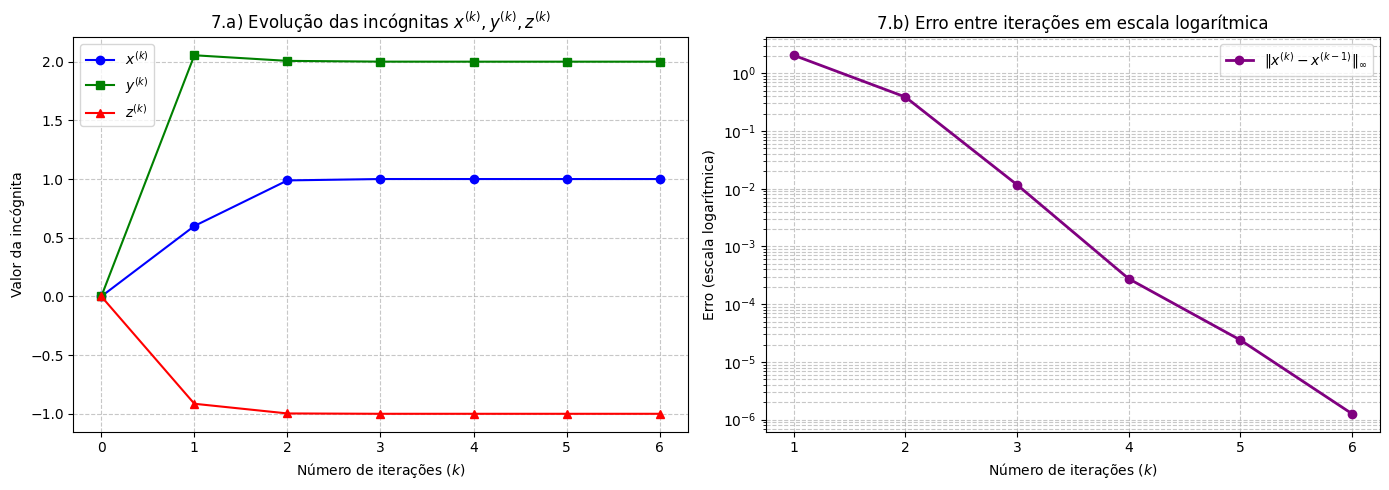

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 7.a) Evolução de x^(k), y^(k) e z^(k) em função de k
ax1.plot(history_k, history_x, "o-", label="$x^{(k)}$", color="blue")
ax1.plot(history_k, history_y, "s-", label="$y^{(k)}$", color="green")
ax1.plot(history_k, history_z, "^-", label="$z^{(k)}$", color="red")
ax1.set_xlabel("Número de iterações ($k$)")
ax1.set_ylabel("Valor da incógnita")
ax1.set_title("7.a) Evolução das incógnitas $x^{(k)}, y^{(k)}, z^{(k)}$")
ax1.set_xticks(history_k)
ax1.grid(True, linestyle="--", alpha=0.7)
ax1.legend()

# 7.b) Erro entre iterações em escala logarítmica em função de k
# Ignora-se k=0 pois não tem erro calculado
k_errors = history_k[1:]
err_values = history_err[1:]

ax2.plot(
    k_errors,
    err_values,
    "o-",
    color="purple",
    linewidth=2,
    label="$\|x^{(k)} - x^{(k-1)}\|_\infty$",
)
ax2.set_yscale("log")
ax2.set_xlabel("Número de iterações ($k$)")
ax2.set_ylabel("Erro (escala logarítmica)")
ax2.set_title("7.b) Erro entre iterações em escala logarítmica")
ax2.set_xticks(k_errors)
ax2.grid(True, which="both", linestyle="--", alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.show()